In [1]:
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import (
    plot_bloch_multivector,
    plot_histogram,
    plot_state_qsphere,
)

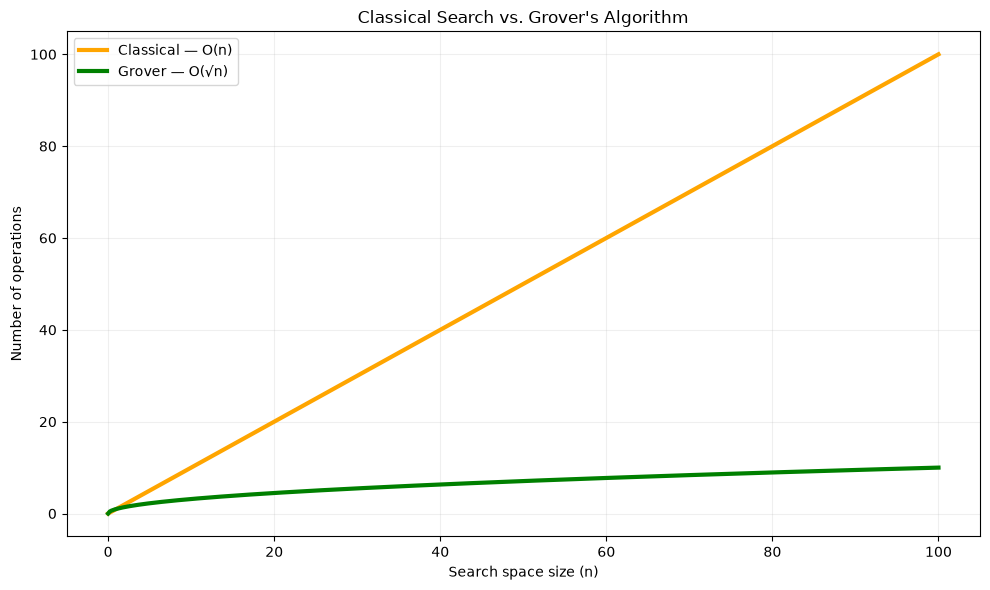

In [2]:
import numpy as np
import matplotlib.pyplot as plt

n = np.linspace(0, 100, 500)

plt.figure(figsize=(10, 6))

plt.plot(n, n, color="orange", linewidth=3, label="Classical — O(n)")
plt.plot(n, np.sqrt(n), color="green", linewidth=3, label="Grover — O(√n)")

plt.xlabel("Search space size (n)")
plt.ylabel("Number of operations")
plt.title("Classical Search vs. Grover's Algorithm")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [3]:
SHOTS = 1024
BASIS = [f"{i:03b}" for i in range(8)]

def show_figure(fig):
    display(fig)
    plt.close(fig)


def show_step(qc: QuantumCircuit, title: str):
    """Нарисовать цепь, выполнить измерения и показать квантовое состояние."""
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}")
    # Показываем исходную цепь без финальных измерений.
    show_figure(qc.draw(output="mpl", fold=20))

    # Точное состояние ДО измерения (доступно только в симуляции).
    state = Statevector.from_instruction(qc)

    # Воспроизводим статистику 4096 измерений из идеального Statevector.
    # Дополнительный qiskit-aer не нужен; аппаратный шум здесь не моделируется.
    state.seed(42)
    sampled_counts = state.sample_counts(shots=SHOTS)
    counts = {bits: sampled_counts.get(bits, 0) for bits in BASIS}

    show_figure(plot_histogram(counts, title=f"Результаты {SHOTS} измерений"))

    # Каждая сфера Блоха — состояние ОДНОГО кубита.
    # Корреляции между кубитами на этих сферах не видны.
    show_figure(plot_bloch_multivector(state, title="Bloch: q0=C, q1=B, q2=A"))

    # Размер точек показывает вероятность; цвет — относительную фазу.
    show_figure(plot_state_qsphere(
        state,
        show_state_labels=True,
        show_state_phases=True,
        use_degrees=True,
    ))

    print("\nТочные амплитуды и вероятности (Statevector):")
    for bits, amplitude, probability in zip(BASIS, state.data, state.probabilities()):
        print(f"|{bits}⟩  amplitude={amplitude.real:+.4f}{amplitude.imag:+.4f}j"
              f"   P={probability:7.2%}")
    print(f"\nP(правильный результат 101) = {state.probabilities()[5]:.4%}")
    return state


In [4]:
def compute_checks(qc: QuantumCircuit):
    """Вычисляем три флага прямо в трёх кубитах, без ancilla."""
    qc.cx(1, 0)  # C <- B XOR C
    qc.cx(1, 2)  # A <- A XOR B
    qc.cx(2, 1)  # B <- исходное A


def uncompute_checks(qc: QuantumCircuit):
    """Обращаем вычисления в строго обратном порядке."""
    qc.cx(2, 1)
    qc.cx(1, 2)
    qc.cx(1, 0)


def oracle(qc: QuantumCircuit):
    compute_checks(qc)
    qc.ccz(0, 1, 2)  # Фазовый знак -1 для единственного валидного варианта
    uncompute_checks(qc)


def diffuser(qc: QuantumCircuit):
    qc.h([0, 1, 2])
    qc.x([0, 1, 2])
    qc.ccz(0, 1, 2)
    qc.x([0, 1, 2])
    qc.h([0, 1, 2])


def prepare(qc: QuantumCircuit):
    qc.h([0, 1, 2])


def valid_configuration(a, b, c):
    return (a != b) and (b != c) and (a or c)

valid = [f"{a}{b}{c}" for a in range(2) for b in range(2) for c in range(2)
         if valid_configuration(a, b, c)]
print("Классическая проверка условий:", valid)
assert valid == ["101"]


Классическая проверка условий: ['101']



0 · Исходное состояние


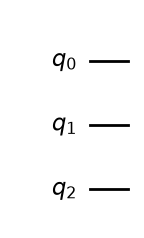

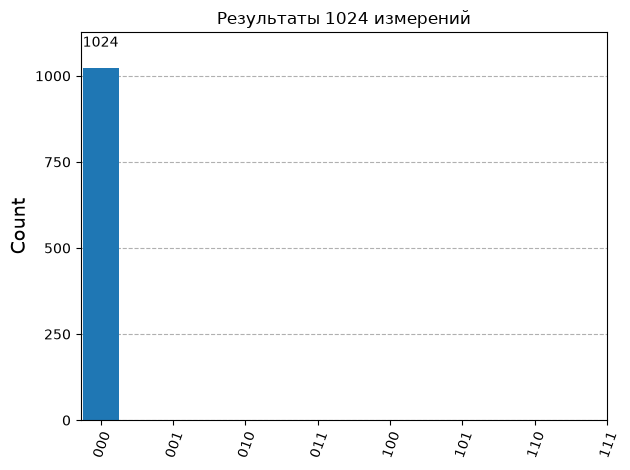

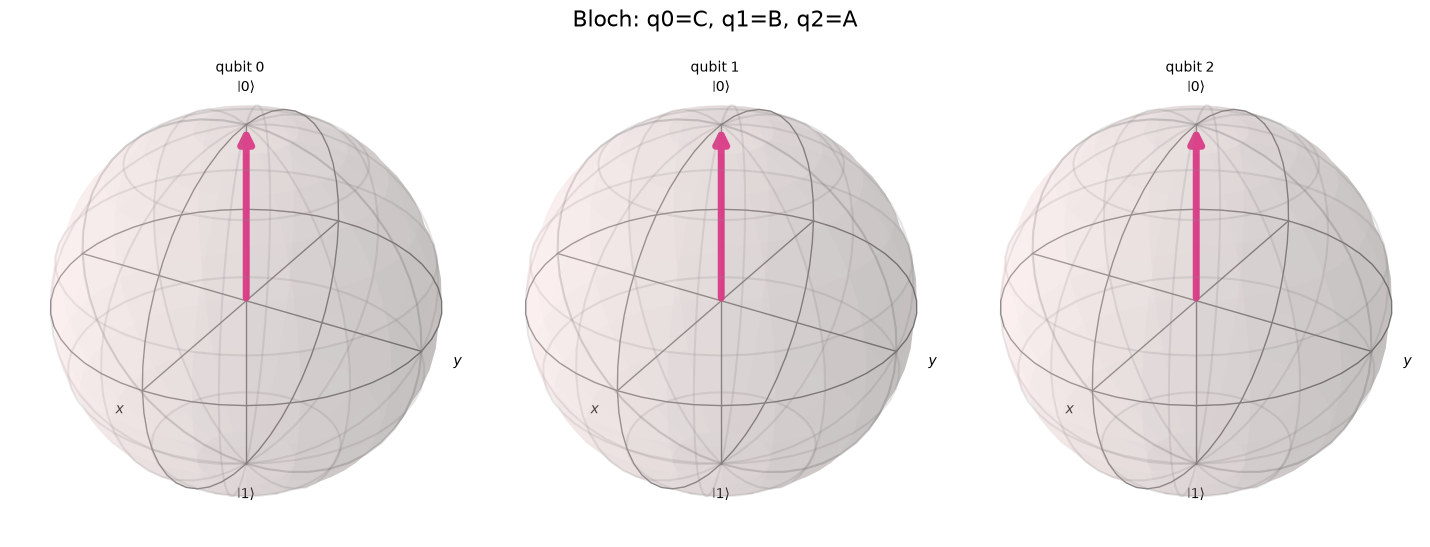

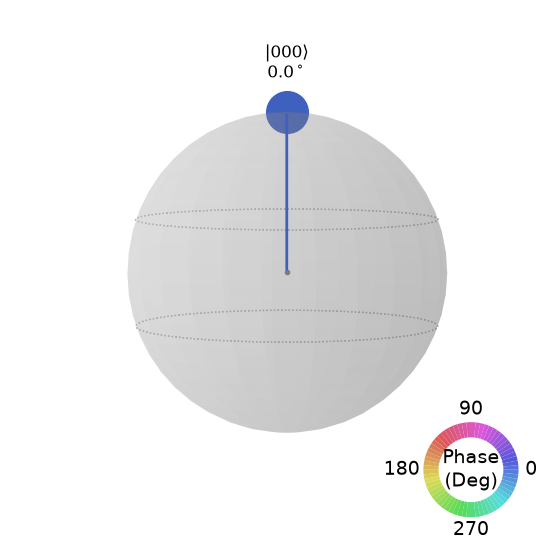


Точные амплитуды и вероятности (Statevector):
|000⟩  amplitude=+1.0000+0.0000j   P=100.00%
|001⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|010⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|011⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|100⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|101⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|110⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|111⟩  amplitude=+0.0000+0.0000j   P=  0.00%

P(правильный результат 101) = 0.0000%


In [5]:
qc = QuantumCircuit(3)
state_0 = show_step(qc, "0 · Исходное состояние")



1 · H(C): две конфигурации


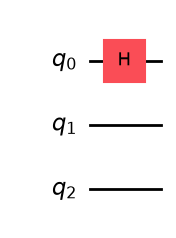

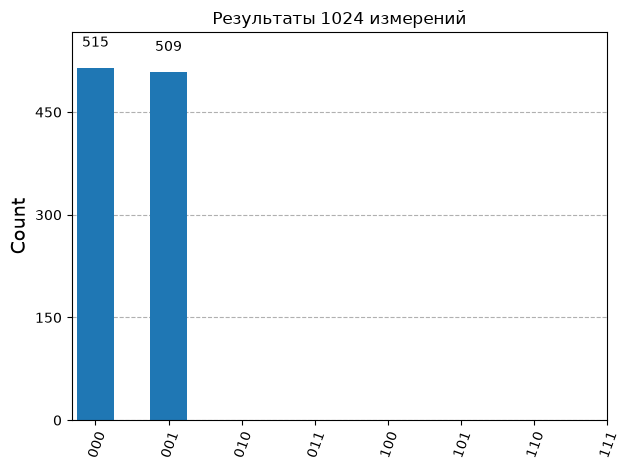

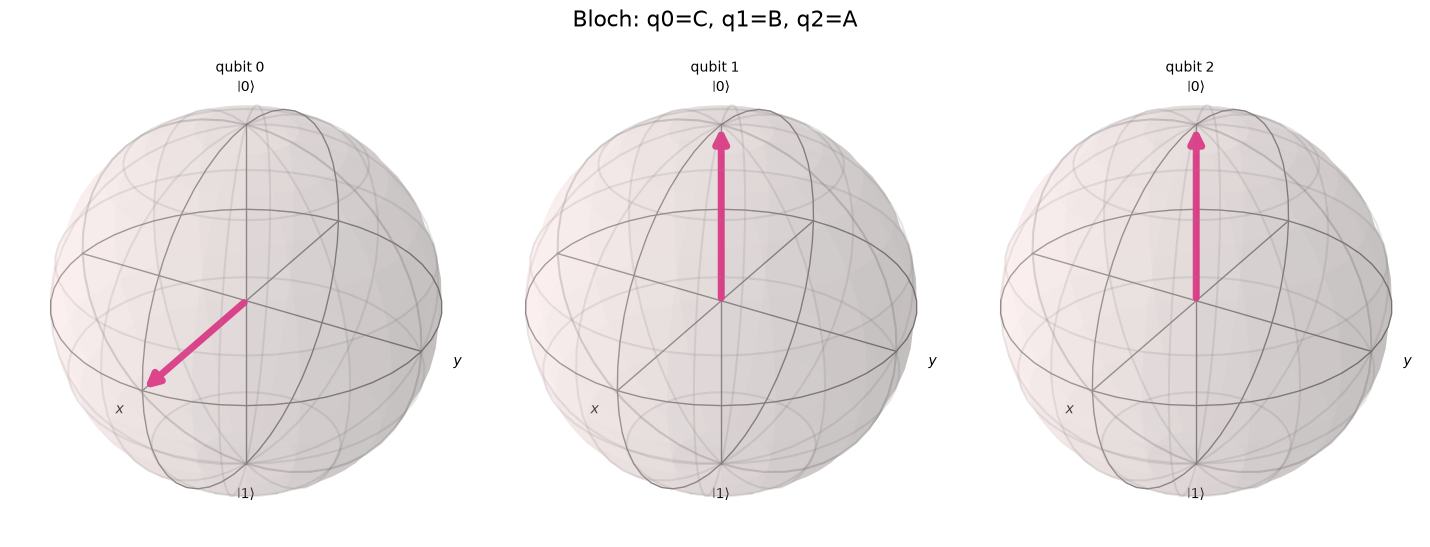

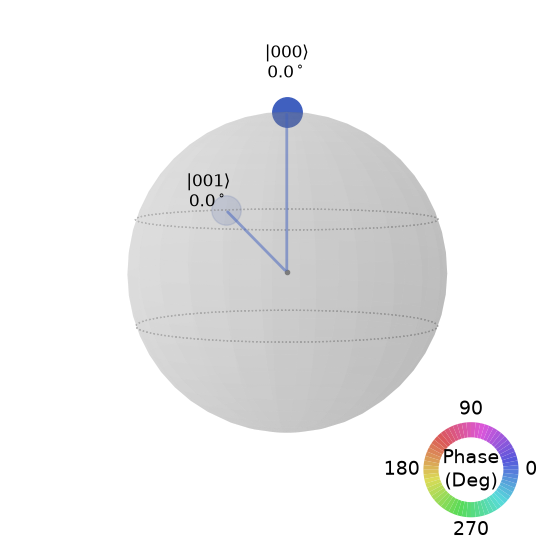


Точные амплитуды и вероятности (Statevector):
|000⟩  amplitude=+0.7071+0.0000j   P= 50.00%
|001⟩  amplitude=+0.7071+0.0000j   P= 50.00%
|010⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|011⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|100⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|101⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|110⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|111⟩  amplitude=+0.0000+0.0000j   P=  0.00%

P(правильный результат 101) = 0.0000%


In [6]:
qc = QuantumCircuit(3)
qc.h(0)
state_1 = show_step(qc, "1 · H(C): две конфигурации")



2 · H(C), H(B): четыре конфигурации


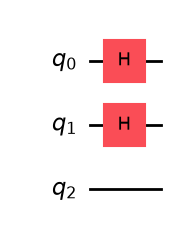

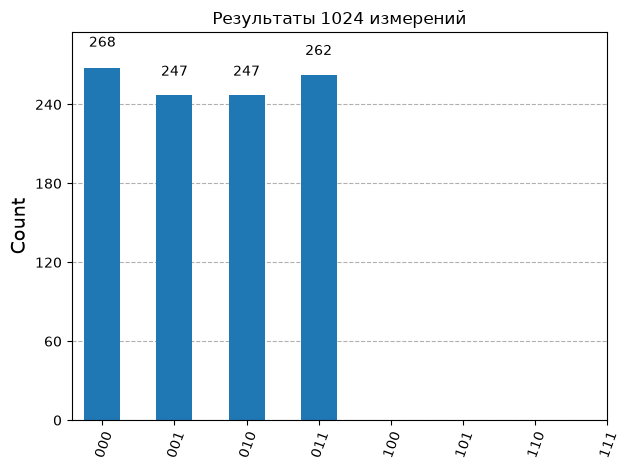

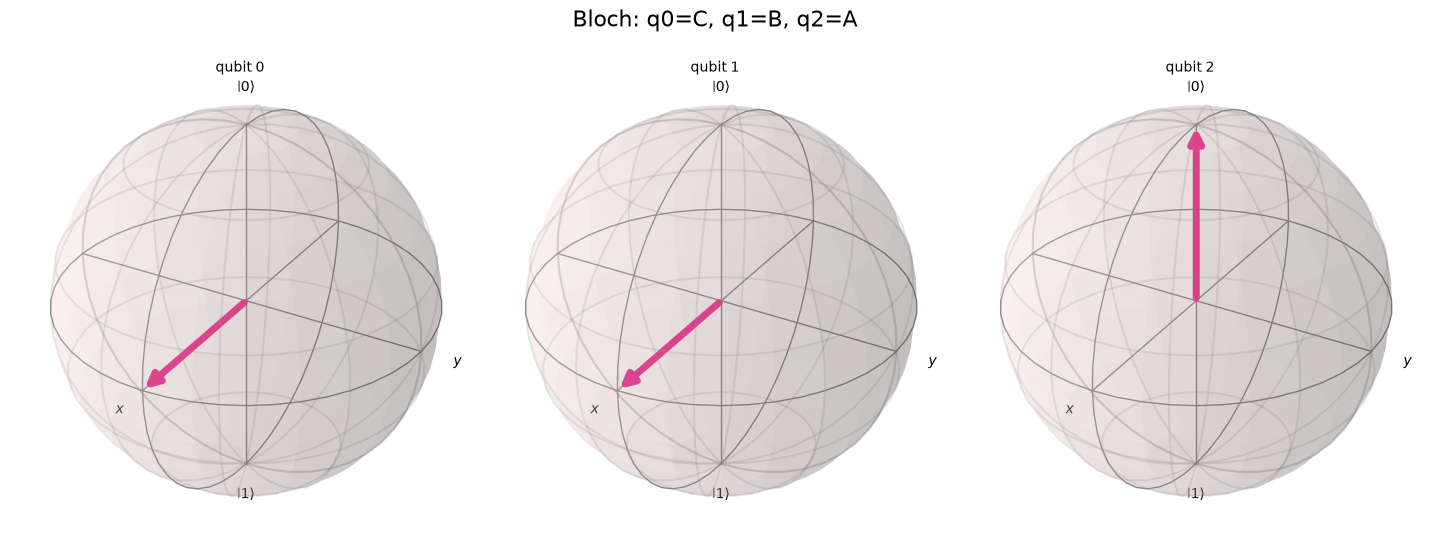

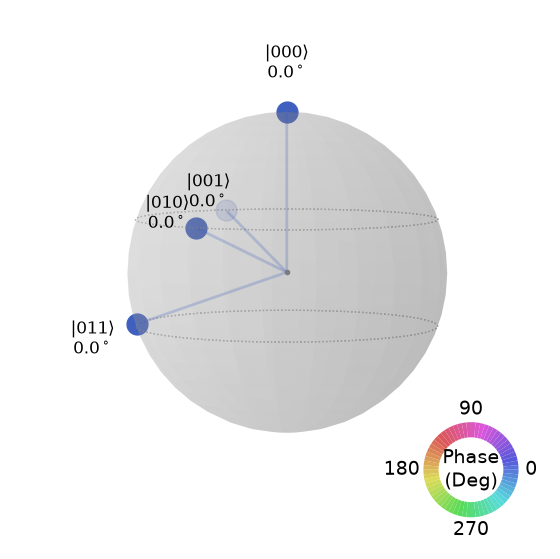


Точные амплитуды и вероятности (Statevector):
|000⟩  amplitude=+0.5000+0.0000j   P= 25.00%
|001⟩  amplitude=+0.5000+0.0000j   P= 25.00%
|010⟩  amplitude=+0.5000+0.0000j   P= 25.00%
|011⟩  amplitude=+0.5000+0.0000j   P= 25.00%
|100⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|101⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|110⟩  amplitude=+0.0000+0.0000j   P=  0.00%
|111⟩  amplitude=+0.0000+0.0000j   P=  0.00%

P(правильный результат 101) = 0.0000%


In [7]:
qc = QuantumCircuit(3)
qc.h(0)
qc.h(1)
state_2 = show_step(qc, "2 · H(C), H(B): четыре конфигурации")



3 · Суперпозиция: восемь конфигураций


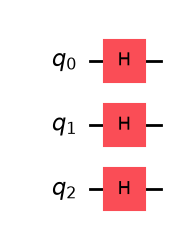

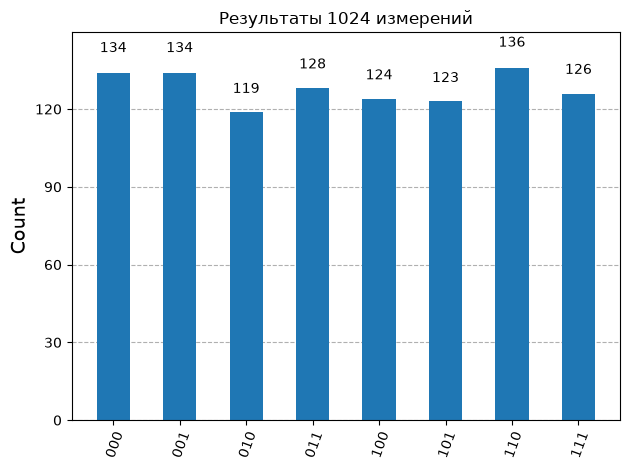

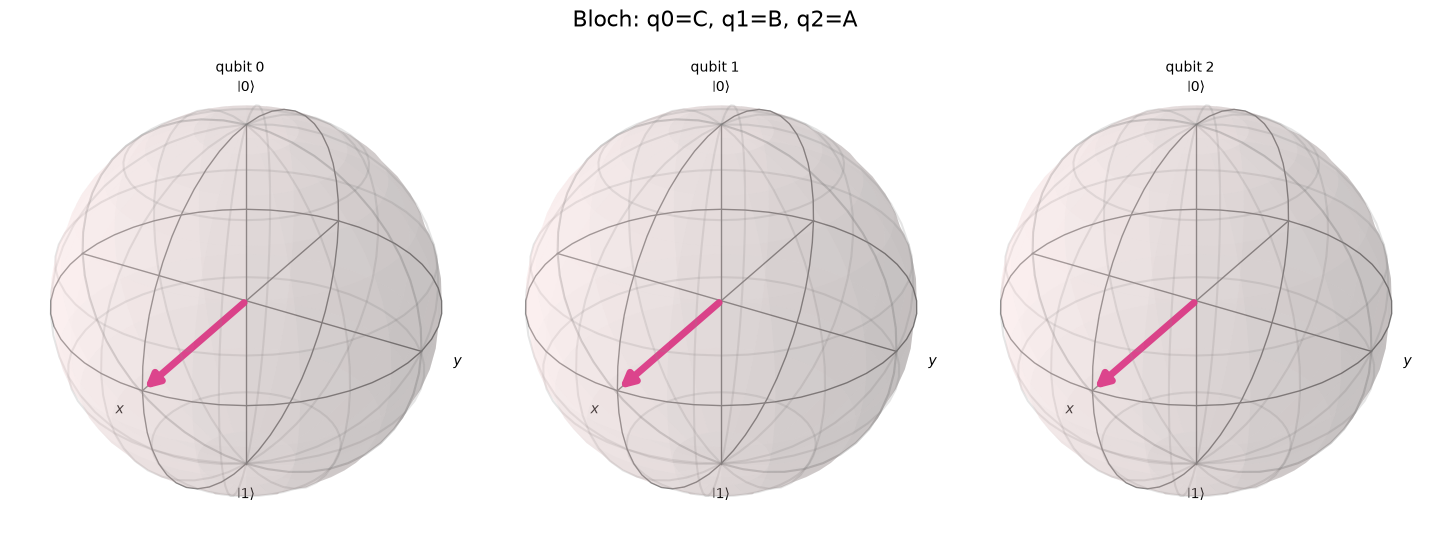

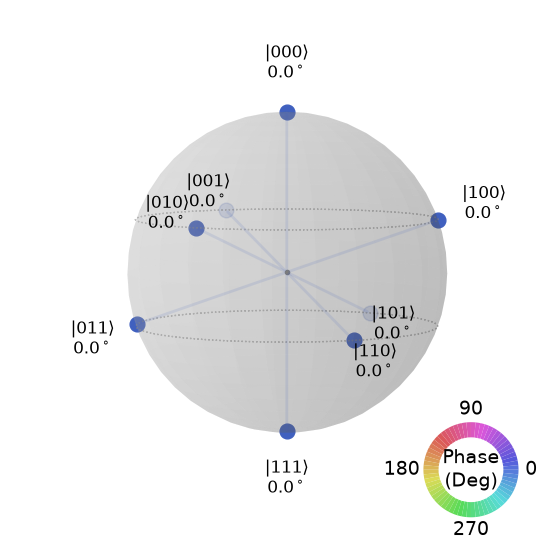


Точные амплитуды и вероятности (Statevector):
|000⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|001⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|010⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|011⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|100⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|101⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|110⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|111⟩  amplitude=+0.3536+0.0000j   P= 12.50%

P(правильный результат 101) = 12.5000%


In [8]:
qc = QuantumCircuit(3)
prepare(qc)
state_3 = show_step(qc, "3 · Суперпозиция: восемь конфигураций")



4 · Три CNOT вычисляют условия


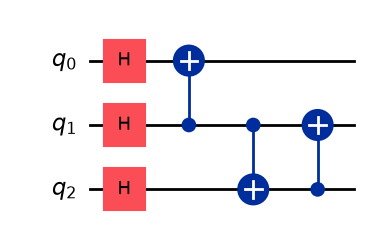

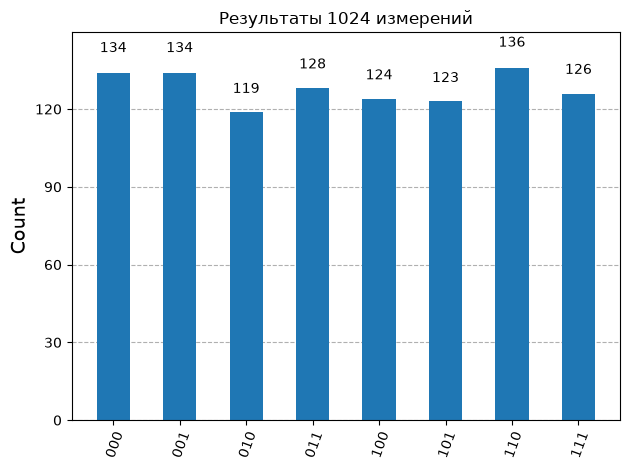

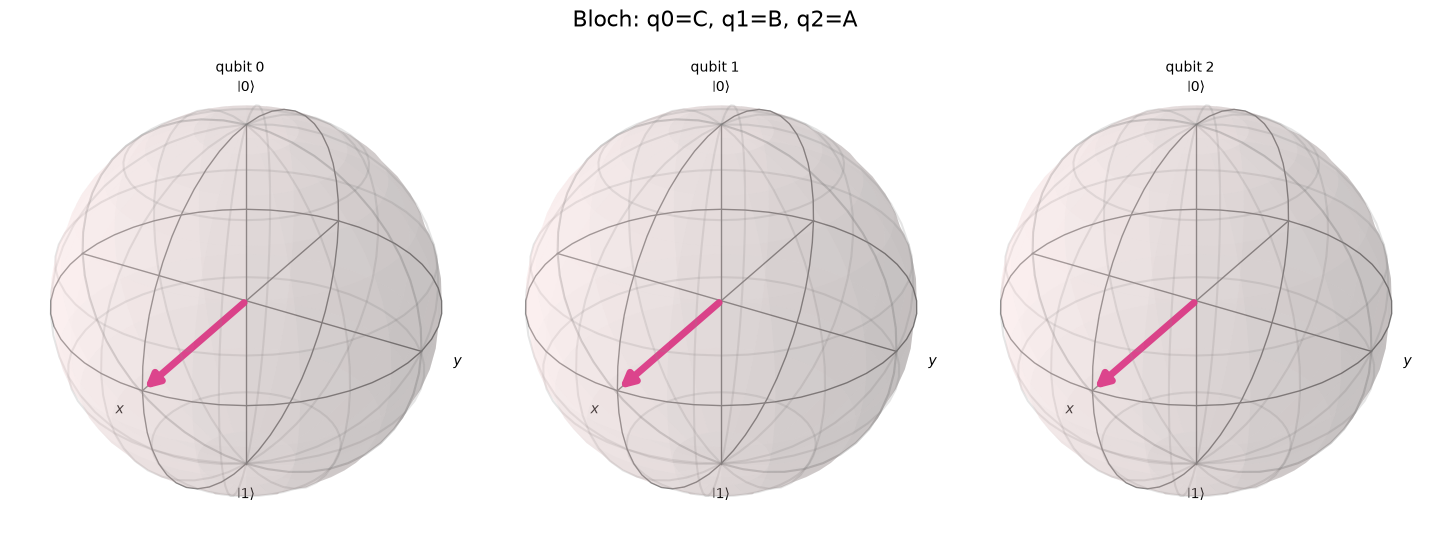

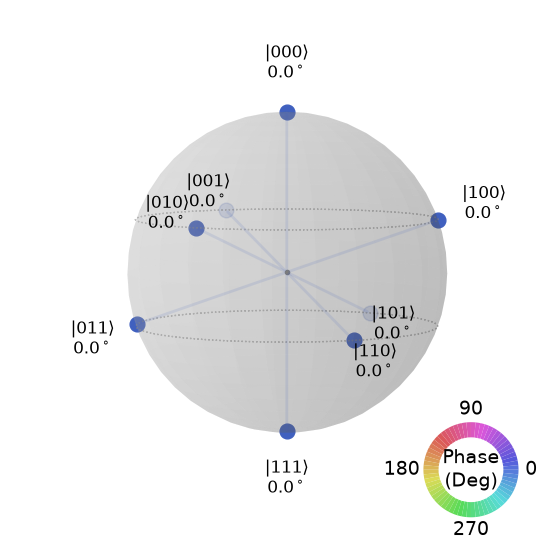


Точные амплитуды и вероятности (Statevector):
|000⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|001⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|010⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|011⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|100⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|101⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|110⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|111⟩  amplitude=+0.3536+0.0000j   P= 12.50%

P(правильный результат 101) = 12.5000%


In [9]:
qc = QuantumCircuit(3)
prepare(qc)
compute_checks(qc)
state_4 = show_step(qc, "4 · Три CNOT вычисляют условия")



5 · CCZ: фазовая маркировка


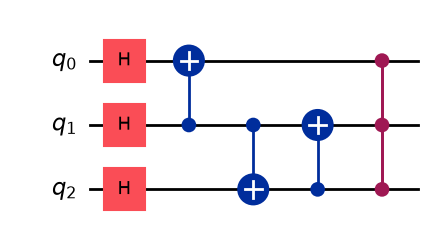

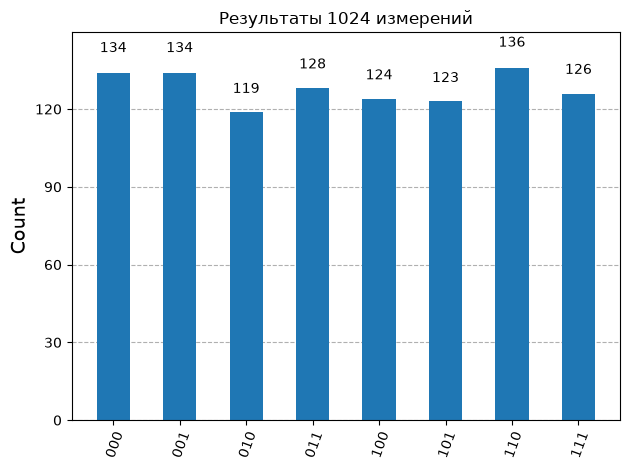

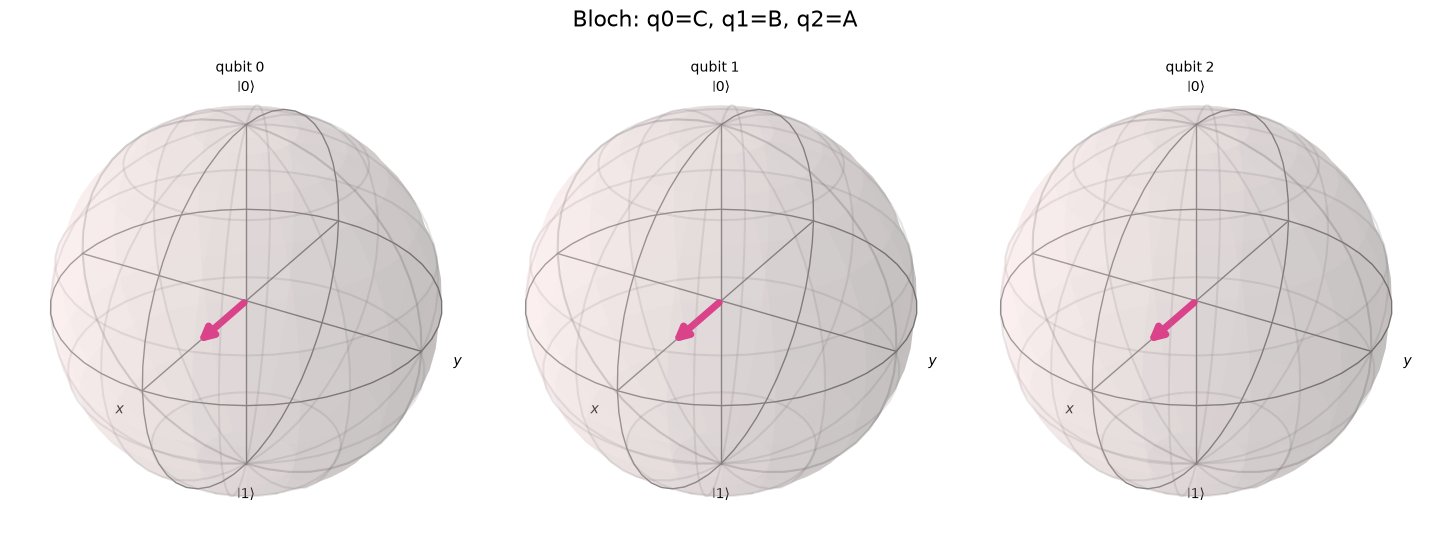

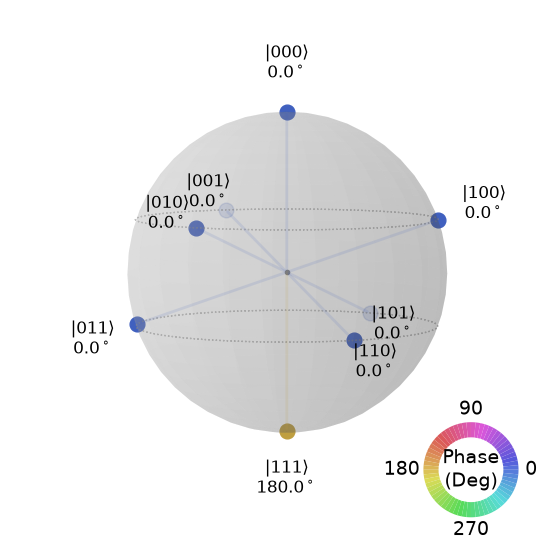


Точные амплитуды и вероятности (Statevector):
|000⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|001⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|010⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|011⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|100⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|101⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|110⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|111⟩  amplitude=-0.3536+0.0000j   P= 12.50%

P(правильный результат 101) = 12.5000%


In [10]:
qc = QuantumCircuit(3)
prepare(qc)
compute_checks(qc)
qc.ccz(0, 1, 2)
state_5 = show_step(qc, "5 · CCZ: фазовая маркировка")



6 · Полный оракул: отмечен |101⟩


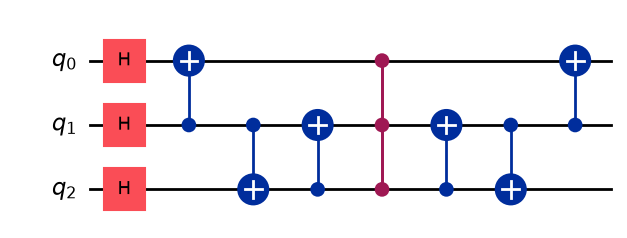

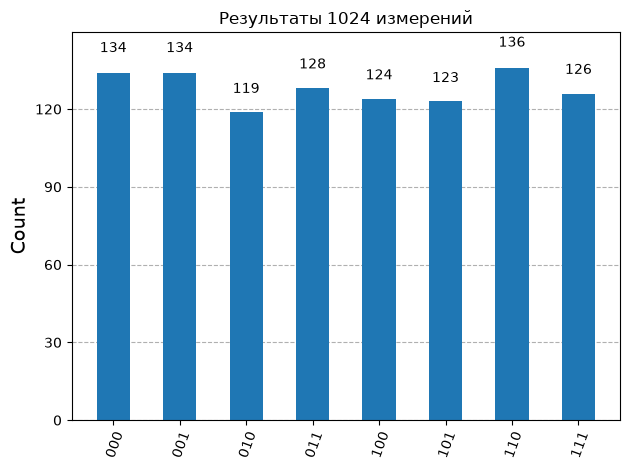

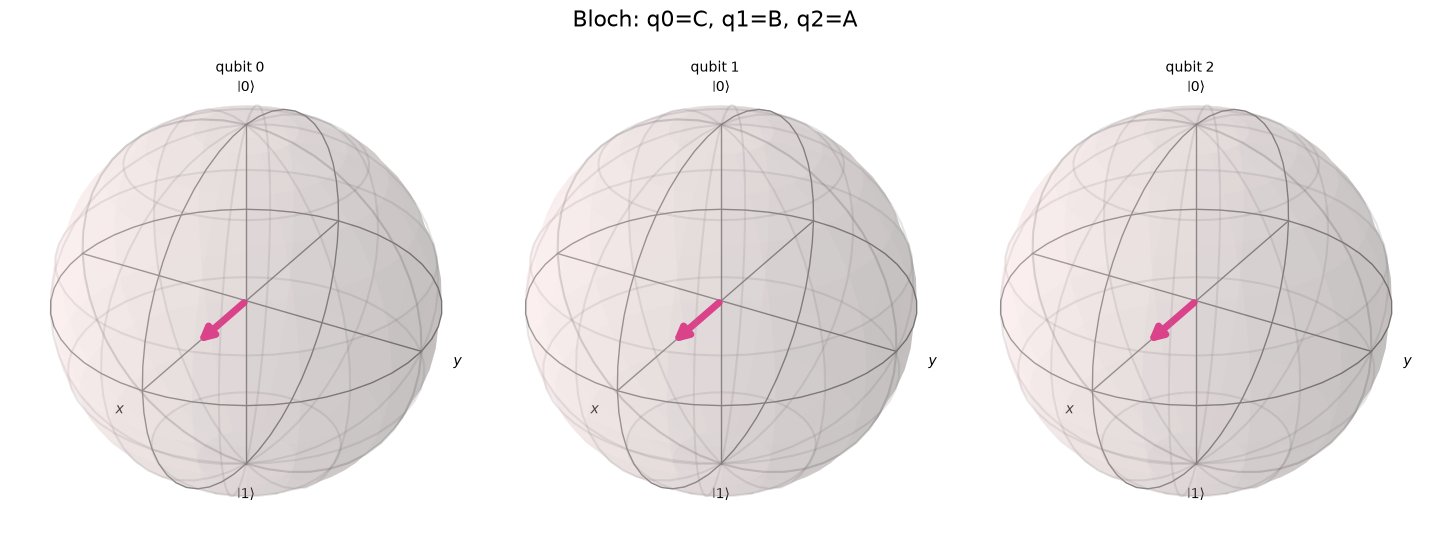

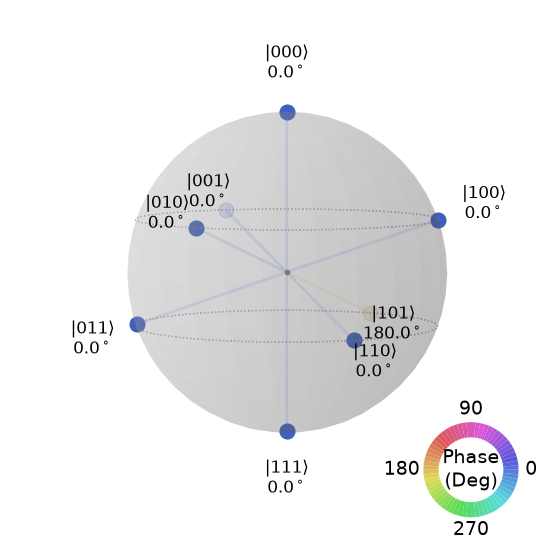


Точные амплитуды и вероятности (Statevector):
|000⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|001⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|010⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|011⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|100⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|101⟩  amplitude=-0.3536+0.0000j   P= 12.50%
|110⟩  amplitude=+0.3536+0.0000j   P= 12.50%
|111⟩  amplitude=+0.3536+0.0000j   P= 12.50%

P(правильный результат 101) = 12.5000%


In [11]:
qc = QuantumCircuit(3)
prepare(qc)
oracle(qc)
state_6 = show_step(qc, "6 · Полный оракул: отмечен |101⟩")
assert abs(state_6.data[5].real + 1 / (8 ** 0.5)) < 1e-10



7 · Оракул + диффузор: первая итерация


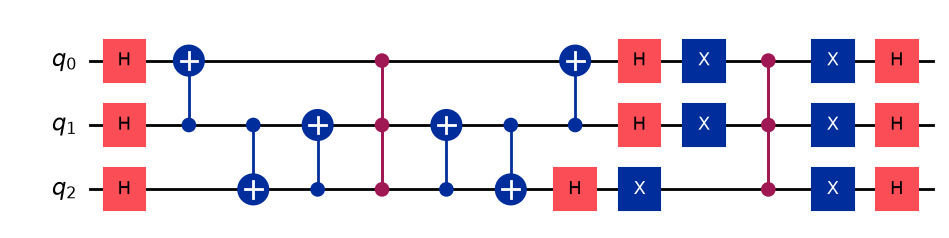

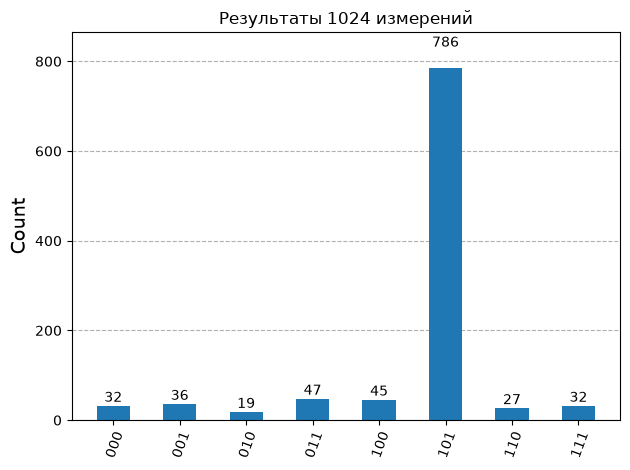

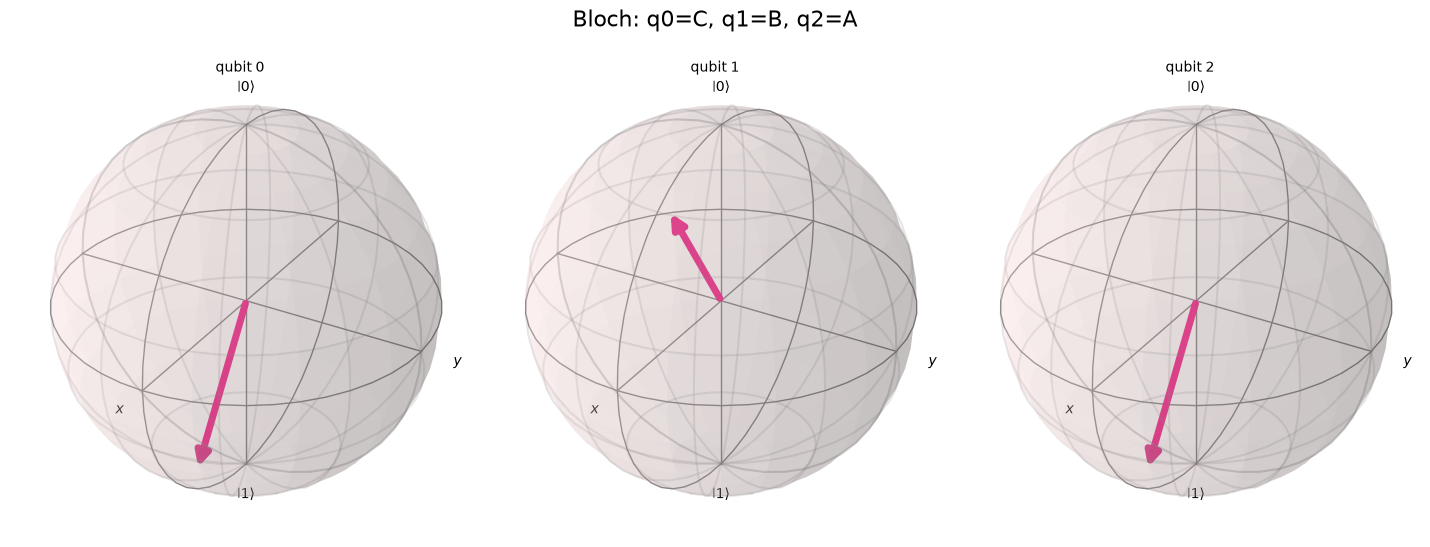

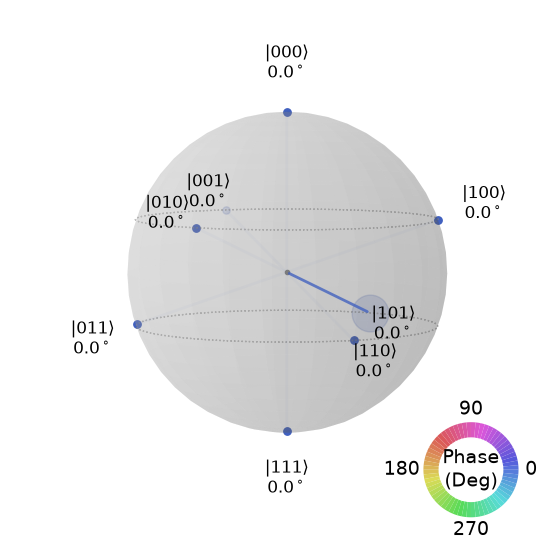


Точные амплитуды и вероятности (Statevector):
|000⟩  amplitude=-0.1768+0.0000j   P=  3.12%
|001⟩  amplitude=-0.1768+0.0000j   P=  3.12%
|010⟩  amplitude=-0.1768+0.0000j   P=  3.12%
|011⟩  amplitude=-0.1768+0.0000j   P=  3.12%
|100⟩  amplitude=-0.1768+0.0000j   P=  3.12%
|101⟩  amplitude=-0.8839+0.0000j   P= 78.12%
|110⟩  amplitude=-0.1768+0.0000j   P=  3.12%
|111⟩  amplitude=-0.1768+0.0000j   P=  3.12%

P(правильный результат 101) = 78.1250%


In [12]:
qc = QuantumCircuit(3)
prepare(qc)
oracle(qc)
diffuser(qc)
state_7 = show_step(qc, "7 · Оракул + диффузор: первая итерация")
assert abs(state_7.probabilities()[5] - 0.78125) < 1e-10



8 · Повторный оракул: фаза изменилась


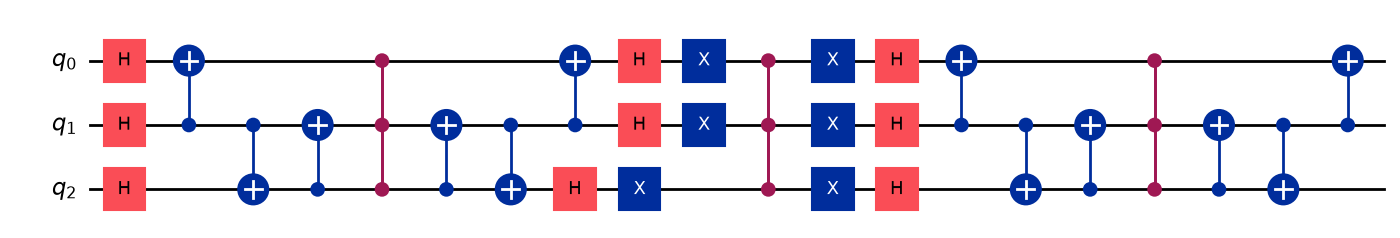

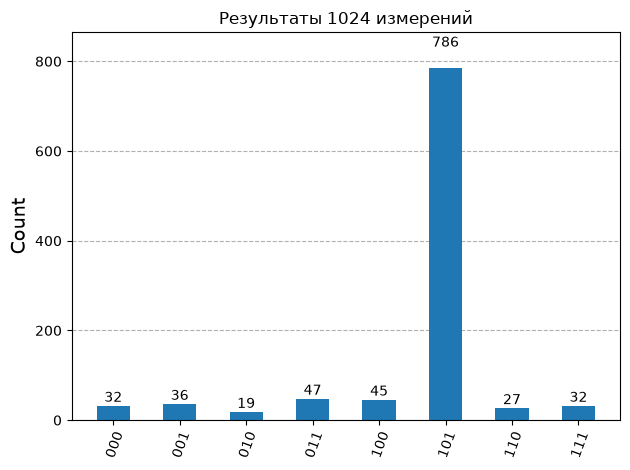

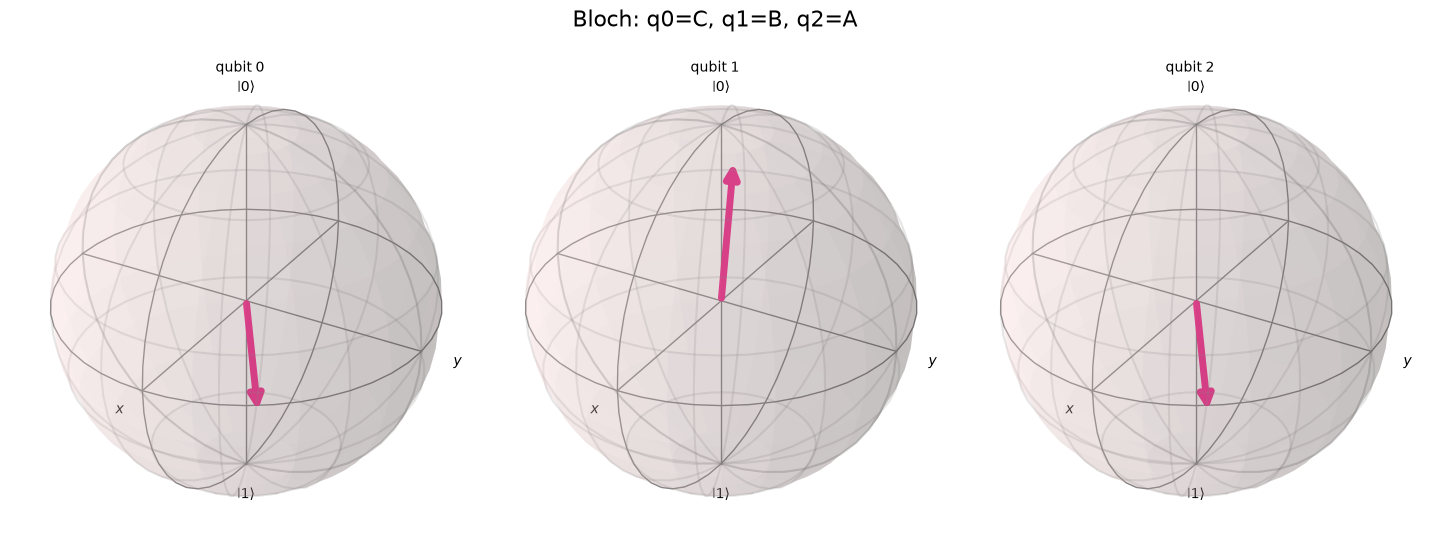

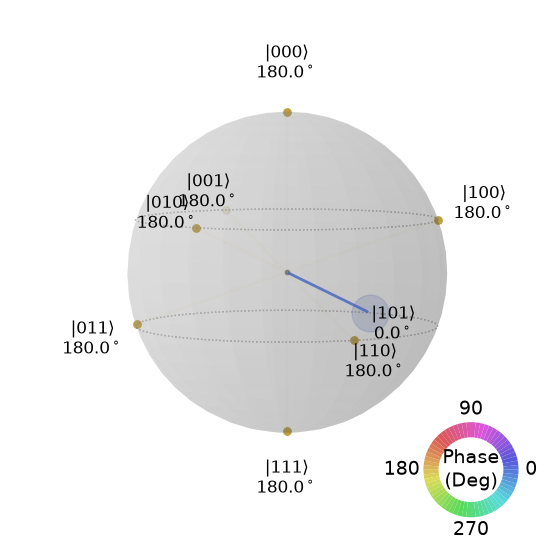


Точные амплитуды и вероятности (Statevector):
|000⟩  amplitude=-0.1768+0.0000j   P=  3.12%
|001⟩  amplitude=-0.1768+0.0000j   P=  3.12%
|010⟩  amplitude=-0.1768+0.0000j   P=  3.12%
|011⟩  amplitude=-0.1768+0.0000j   P=  3.12%
|100⟩  amplitude=-0.1768+0.0000j   P=  3.12%
|101⟩  amplitude=+0.8839+0.0000j   P= 78.12%
|110⟩  amplitude=-0.1768+0.0000j   P=  3.12%
|111⟩  amplitude=-0.1768+0.0000j   P=  3.12%

P(правильный результат 101) = 78.1250%


In [13]:
qc = QuantumCircuit(3)
prepare(qc)
oracle(qc)
diffuser(qc)
oracle(qc)
state_8 = show_step(qc, "8 · Повторный оракул: фаза изменилась")



9 · Итоговая квантовая цепь: 2 итерации


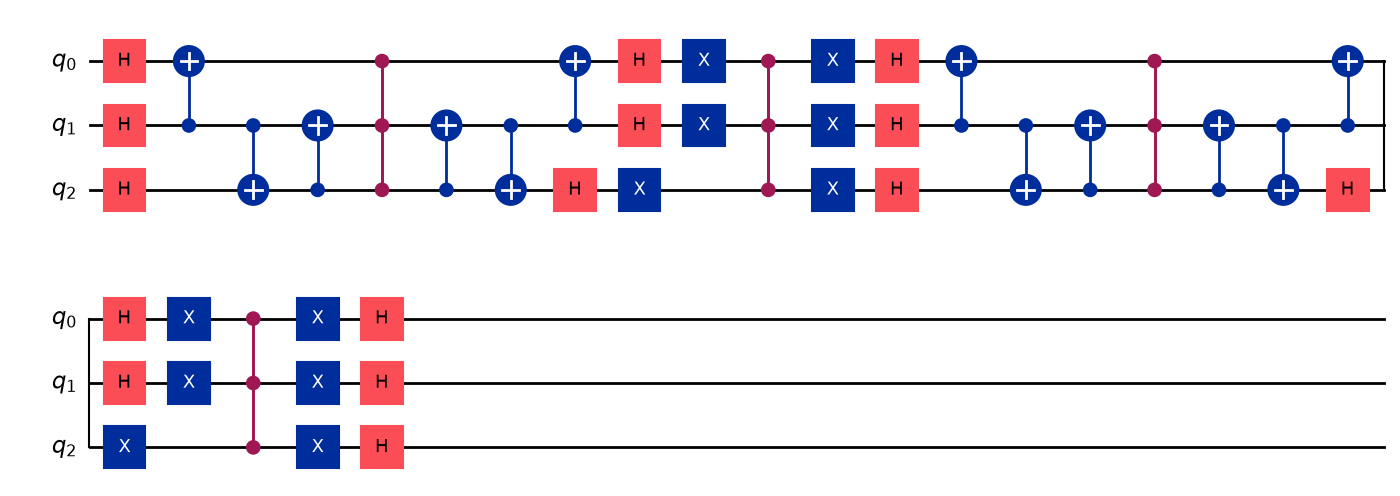

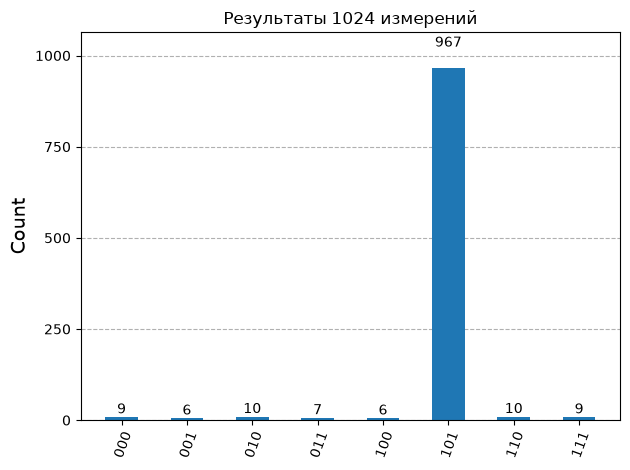

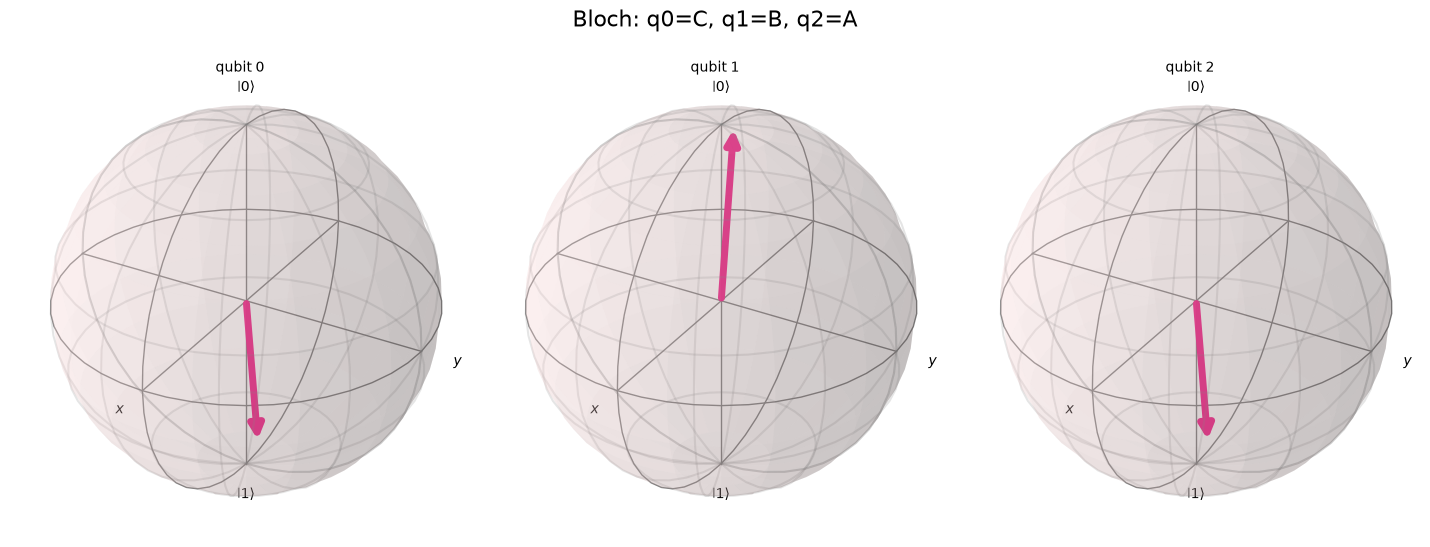

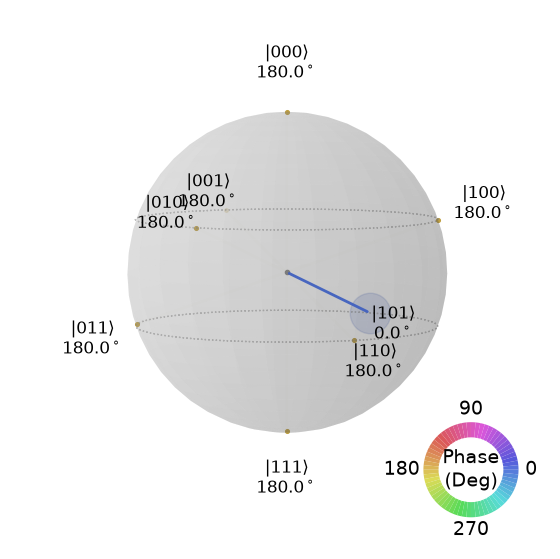


Точные амплитуды и вероятности (Statevector):
|000⟩  amplitude=-0.0884+0.0000j   P=  0.78%
|001⟩  amplitude=-0.0884+0.0000j   P=  0.78%
|010⟩  amplitude=-0.0884+0.0000j   P=  0.78%
|011⟩  amplitude=-0.0884+0.0000j   P=  0.78%
|100⟩  amplitude=-0.0884+0.0000j   P=  0.78%
|101⟩  amplitude=+0.9723+0.0000j   P= 94.53%
|110⟩  amplitude=-0.0884+0.0000j   P=  0.78%
|111⟩  amplitude=-0.0884+0.0000j   P=  0.78%

P(правильный результат 101) = 94.5312%


In [14]:
qc = QuantumCircuit(3)
prepare(qc)
oracle(qc)
diffuser(qc)
oracle(qc)
diffuser(qc)
state_9 = show_step(qc, "9 · Итоговая квантовая цепь: 2 итерации")
assert abs(state_9.probabilities()[5] - 0.9453125) < 1e-10
